# Notebook 03 — Cohort Retensi, Segmentasi RFM & Uji A/B — KUNCI JAWABAN

**Dataset:** TokoKita (fiktif), toko online dengan 6 tabel: `customers`, `products`, `orders`, `order_items`, `marketing`, `web_events`.

**Cara memakai**
- **Google Colab:** File → Upload notebook → pilih file ini. Jalankan sel pertama, lalu upload 6 file CSV dari folder `latihan/data`.
- **Jupyter/VS Code di laptop:** buka langsung dari folder `latihan/python`; CSV dibaca otomatis dari `latihan/data`.

Notebook lanjutan untuk Level 8 (Analisis Bisnis Terapan).
> Revenue baris = `qty × harga_satuan × (1 − diskon)`. Pendapatan hanya dihitung dari order berstatus **selesai**.

In [1]:
import os
import pandas as pd
import numpy as np

# ── Google Colab: jalankan sel ini, lalu upload 6 file CSV dari folder latihan/data ──
try:
    from google.colab import files  # noqa
    if not os.path.exists("orders.csv"):
        files.upload()
except ImportError:
    pass

DATA = "" if os.path.exists("orders.csv") else "../data/"   # di laptop: notebook ada di latihan/python, CSV di latihan/data
customers   = pd.read_csv(DATA + "customers.csv",   parse_dates=["tgl_daftar"])
products    = pd.read_csv(DATA + "products.csv")
orders      = pd.read_csv(DATA + "orders.csv",      parse_dates=["tgl_order"])
order_items = pd.read_csv(DATA + "order_items.csv")
marketing   = pd.read_csv(DATA + "marketing.csv",   parse_dates=["minggu"])
web_events  = pd.read_csv(DATA + "web_events.csv",  parse_dates=["tanggal"])
print({n: len(d) for n, d in [("customers", customers), ("products", products), ("orders", orders),
                              ("order_items", order_items), ("marketing", marketing), ("web_events", web_events)]})

{'customers': 600, 'products': 40, 'orders': 1332, 'order_items': 2217, 'marketing': 288, 'web_events': 5030}


## 1. Siapkan data order selesai
Buat `ok` = order selesai + kolom `revenue` per order (gabungkan dengan order_items).

In [2]:
rev = order_items.assign(revenue=order_items.qty * order_items.harga_satuan * (1 - order_items.diskon)).groupby('order_id', as_index=False)['revenue'].sum()
ok = orders[orders.status == 'selesai'].merge(rev, on='order_id')
ok.head()

,order_id,customer_id,tgl_order,status,metode_bayar,revenue
0,O00001,C0001,2025-01-15,selesai,Transfer Bank,219000.0
1,O00002,C0002,2025-01-19,selesai,Transfer Bank,160200.0
2,O00003,C0003,2025-01-22,selesai,E-Wallet,667000.0
3,O00004,C0004,2025-01-23,selesai,E-Wallet,310400.0
4,O00005,C0005,2025-01-26,selesai,COD,1277000.0


## 2. Cohort retensi bulanan
Cohort = bulan order pertama. Buat tabel retensi (% pelanggan aktif di bulan ke-0, 1, 2, …) dan heatmap 7 bulan pertama.

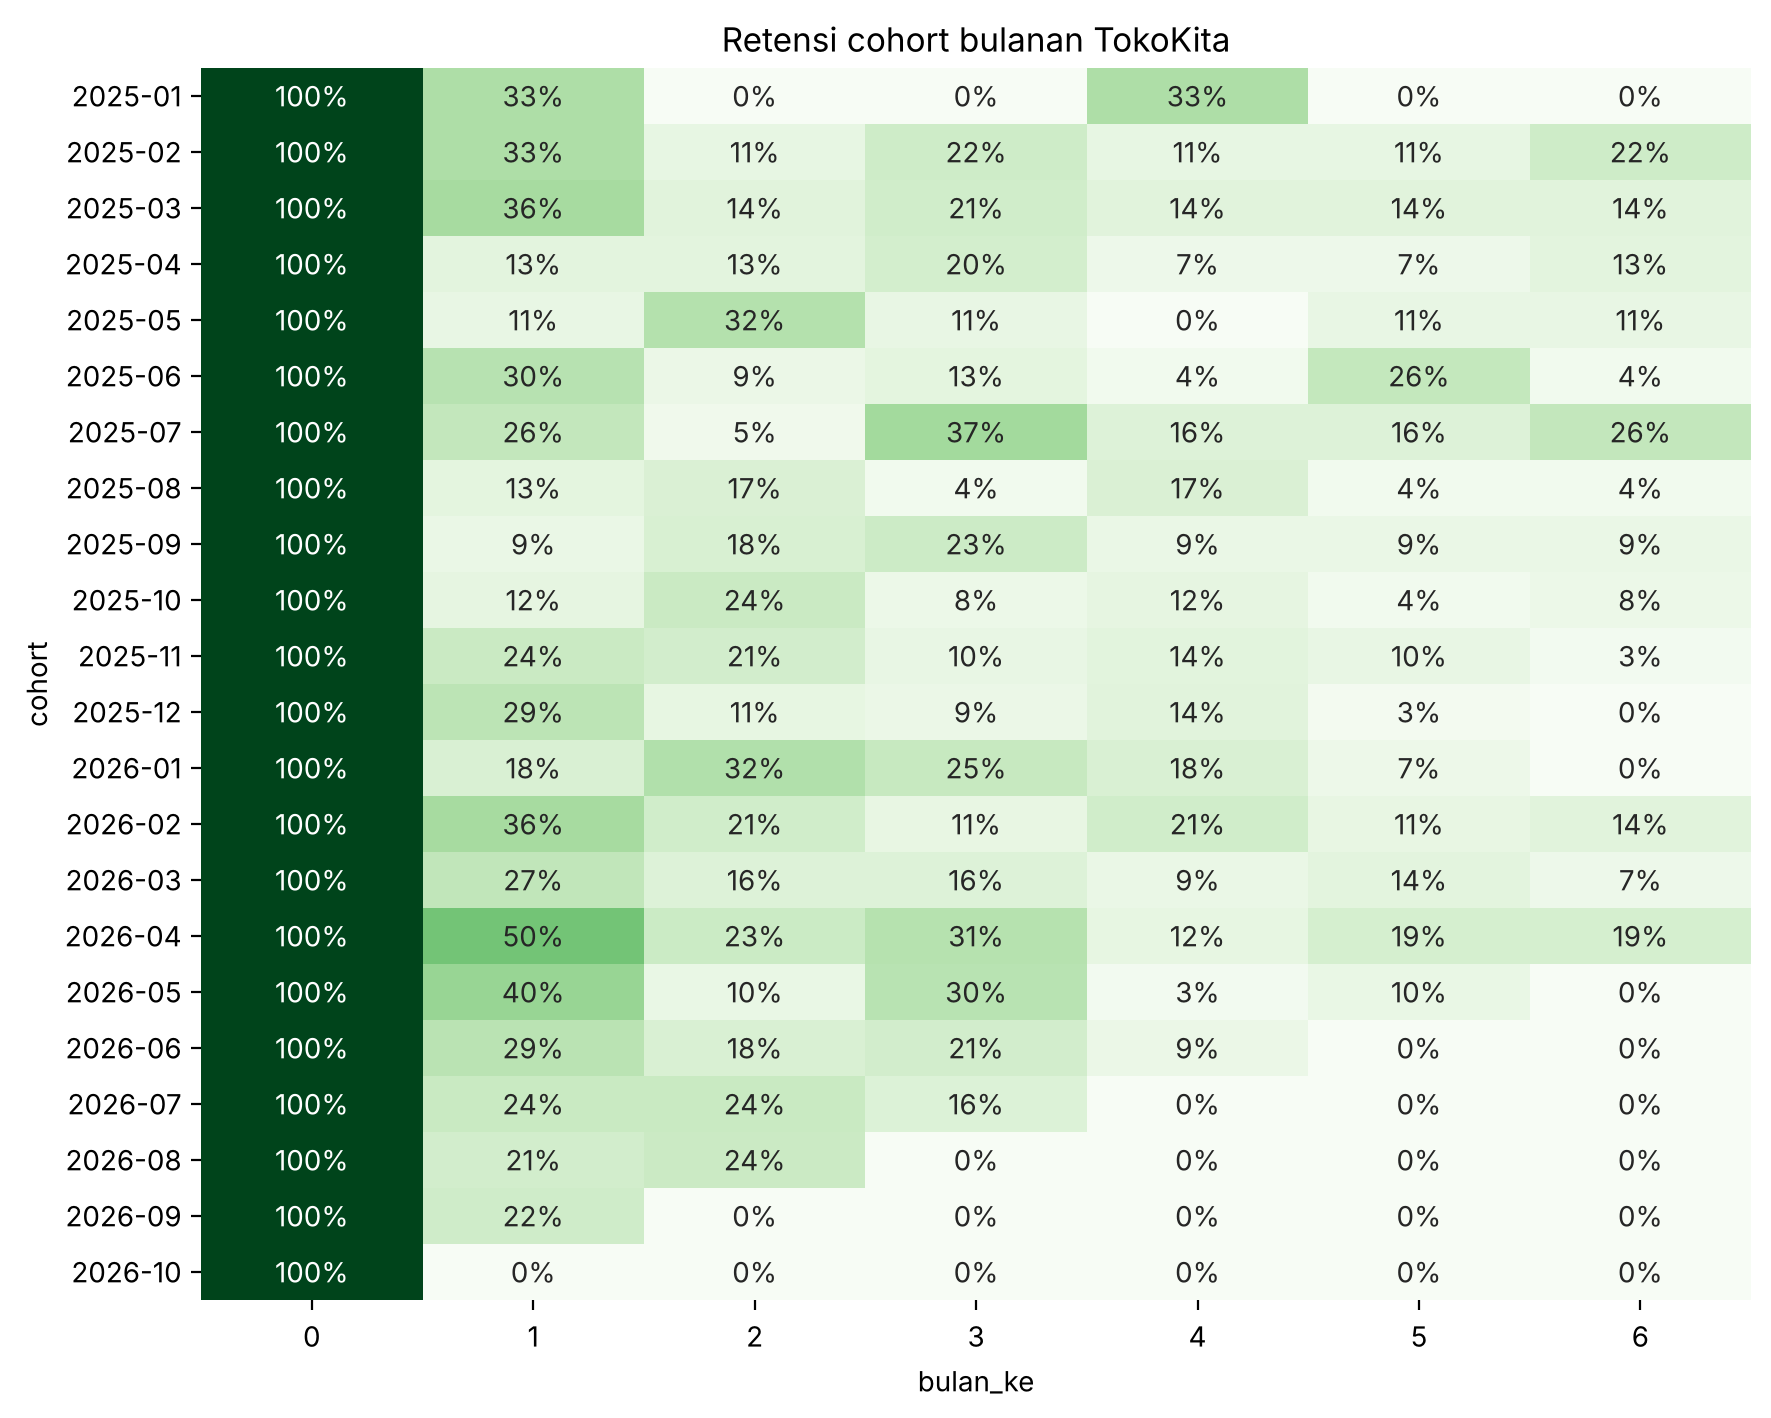

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
ok['bulan'] = ok.tgl_order.dt.to_period('M')
ok['cohort'] = ok.groupby('customer_id')['bulan'].transform('min')
ok['bulan_ke'] = (ok.bulan - ok.cohort).apply(lambda x: x.n)
tabel = ok.groupby(['cohort', 'bulan_ke'])['customer_id'].nunique().unstack(fill_value=0)
retensi = tabel.div(tabel[0], axis=0)
plt.figure(figsize=(10, 8))
sns.heatmap(retensi.iloc[:, :7], annot=True, fmt='.0%', cmap='Greens', cbar=False)
plt.title('Retensi cohort bulanan TokoKita'); plt.show()

## 3. RFM
Hitung Recency (hari sejak order terakhir s.d. 2026-11-01), Frequency (jumlah order), Monetary (total belanja) per pelanggan, lalu skor 1–5 dengan `pd.qcut`.

In [4]:
acuan = pd.Timestamp('2026-11-01')
rfm = ok.groupby('customer_id').agg(recency=('tgl_order', lambda s: (acuan - s.max()).days), frequency=('order_id', 'nunique'), monetary=('revenue', 'sum'))
rfm['R'] = pd.qcut(rfm.recency, 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F'] = pd.qcut(rfm.frequency.rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M'] = pd.qcut(rfm.monetary, 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm.head()

,recency,frequency,monetary,R,F,M
customer_id,,,,,,
C0001,624,2,816000.0,1,3,4
C0002,623,3,298400.0,1,4,2
C0003,530,3,1250000.0,1,4,4
C0004,647,1,310400.0,1,1,2
C0005,526,2,1626000.0,1,3,5


## 4. Segmen RFM
Buat segmen: **Champions** (R≥4 & F≥4), **Loyal** (F≥4), **Pelanggan Baru** (R≥4 & F≤2), **At Risk** (R≤2 & F≥3), **Hibernating** (lainnya dengan R≤2), **Perlu Perhatian** (sisanya). Hitung jumlah pelanggan & % revenue per segmen.

In [5]:
def segmen(r):
    if r.R >= 4 and r.F >= 4: return 'Champions'
    if r.F >= 4: return 'Loyal'
    if r.R >= 4 and r.F <= 2: return 'Pelanggan Baru'
    if r.R <= 2 and r.F >= 3: return 'At Risk'
    if r.R <= 2: return 'Hibernating'
    return 'Perlu Perhatian'
rfm['segmen'] = rfm.apply(segmen, axis=1)
seg = rfm.groupby('segmen').agg(pelanggan=('monetary', 'size'), revenue=('monetary', 'sum'))
seg['pct_revenue'] = (seg.revenue / seg.revenue.sum() * 100).round(1)
seg.sort_values('revenue', ascending=False)

,pelanggan,revenue,pct_revenue
segmen,,,
Loyal,105,155116400.0,32.1
Champions,121,150191700.0,31.1
Hibernating,121,57055300.0,11.8
Perlu Perhatian,103,53814600.0,11.1
At Risk,54,44805700.0,9.3
Pelanggan Baru,60,21894700.0,4.5


## 5. Uji A/B: conversion mobile vs desktop
Gunakan z-test dua proporsi (sesi purchase ÷ sesi view_product). Laporkan selisih (poin persen), CI 95%, dan p-value.

In [6]:
import math
v = web_events[web_events.event == 'view_product'].groupby('device')['session_id'].nunique()
p = web_events[web_events.event == 'purchase'].groupby('device')['session_id'].nunique()
x1, n1, x2, n2 = p['desktop'], v['desktop'], p['mobile'], v['mobile']
p1, p2 = x1 / n1, x2 / n2
pg = (x1 + x2) / (n1 + n2)
z = (p1 - p2) / math.sqrt(pg * (1 - pg) * (1 / n1 + 1 / n2))
pval = math.erfc(abs(z) / math.sqrt(2))
se = math.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
print(f'desktop {p1:.2%} vs mobile {p2:.2%} → selisih {100*(p1-p2):.1f} pp, CI95% ±{196*se:.1f} pp, z={z:.2f}, p={pval:.2g}')

desktop 19.81% vs mobile 11.02% → selisih 8.8 pp, CI95% ±3.0 pp, z=6.36, p=2e-10


## 6. Kesimpulan untuk manajer
Tulis 3–5 kalimat: segmen mana yang harus diprioritaskan, dan rekomendasi untuk funnel mobile.

In [7]:
print('Contoh: Champions & Loyal menyumbang porsi revenue terbesar → program loyalitas. At Risk cukup besar → kampanye win-back. Conversion mobile signifikan lebih rendah dari desktop → perbaiki checkout mobile lalu A/B test.')

Contoh: Champions & Loyal menyumbang porsi revenue terbesar → program loyalitas. At Risk cukup besar → kampanye win-back. Conversion mobile signifikan lebih rendah dari desktop → perbaiki checkout mobile lalu A/B test.


---
Bandingkan dengan jawabanmu. Ingat: ada banyak cara benar untuk menulis kode yang sama.